In [12]:
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics.cluster import contingency_matrix
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder
from scipy.optimize import linear_sum_assignment
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

#Exercise 1

##Apply K-Means with k=3 and k=5

In [2]:

dataset = {
    "Customer": ["C1","C2","C3","C4","C5","C6","C7","C8","C9","C10","C11","C12","C13","C14","C15","C16","C17","C18","C19","C20"],
    "Annual Income (X)": [15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34],
    "Spending Score (Y)": [39,81,6,77,40,76,6,94,15,73,88,17,40,55,82,20,79,35,83,30]
}

# Create DataFrame
df = pd.DataFrame(dataset)
X = df[["Annual Income (X)", "Spending Score (Y)"]]

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# --- Apply K-Means with k = 3 ---
kmeans_3 = KMeans(n_clusters=3, random_state=42, n_init=10)
df_k3 = df.copy()
df_k3['Cluster'] = kmeans_3.fit_predict(X_scaled)

print(" -- K-Means = 3 (Scaled) -- ")
display(df_k3)

# --- Apply K-Means with k = 5 ---
kmeans_5 = KMeans(n_clusters=5, random_state=42, n_init=10)
df_k5 = df.copy()
df_k5['Cluster'] = kmeans_5.fit_predict(X_scaled)

print(" -- K-Means = 5 (Scaled) -- ")
display(df_k5)

 -- K-Means = 3 (Scaled) -- 


,Customer,Annual Income (X),Spending Score (Y),Cluster
0,C1,15,39,2
1,C2,16,81,1
2,C3,17,6,2
3,C4,18,77,1
4,C5,19,40,2
5,C6,20,76,1
6,C7,21,6,2
7,C8,22,94,1
8,C9,23,15,2
9,C10,24,73,1


 -- K-Means = 5 (Scaled) -- 


,Customer,Annual Income (X),Spending Score (Y),Cluster
0,C1,15,39,0
1,C2,16,81,3
2,C3,17,6,4
3,C4,18,77,3
4,C5,19,40,0
5,C6,20,76,3
6,C7,21,6,4
7,C8,22,94,3
8,C9,23,15,4
9,C10,24,73,1


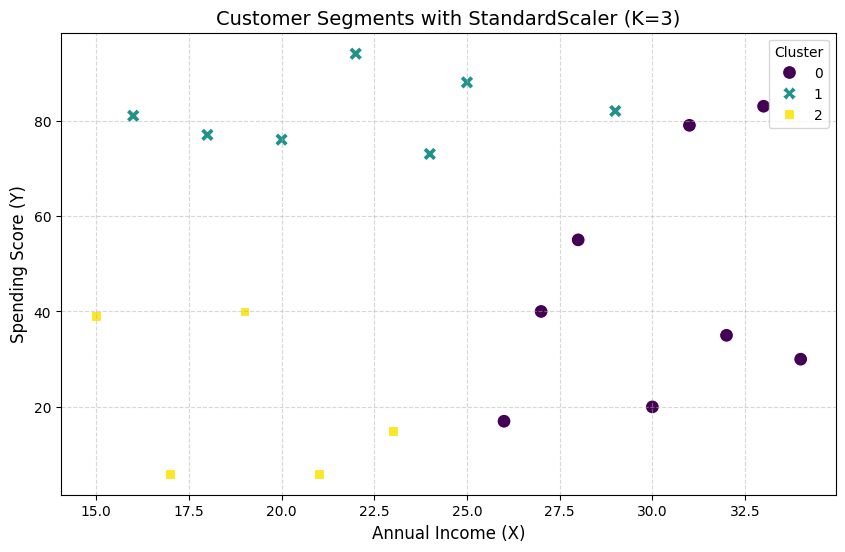

In [3]:
# Generate 2D Scatter plot (k=3)
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x="Annual Income (X)",
    y="Spending Score (Y)",
    hue="Cluster",
    palette="viridis",
    data=df_k3,
    s=100,
    style="Cluster"
)
plt.title("Customer Segments with StandardScaler (K=3)", fontsize=14)
plt.xlabel("Annual Income (X)", fontsize=12)
plt.ylabel("Spending Score (Y)", fontsize=12)
plt.legend(title="Cluster")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

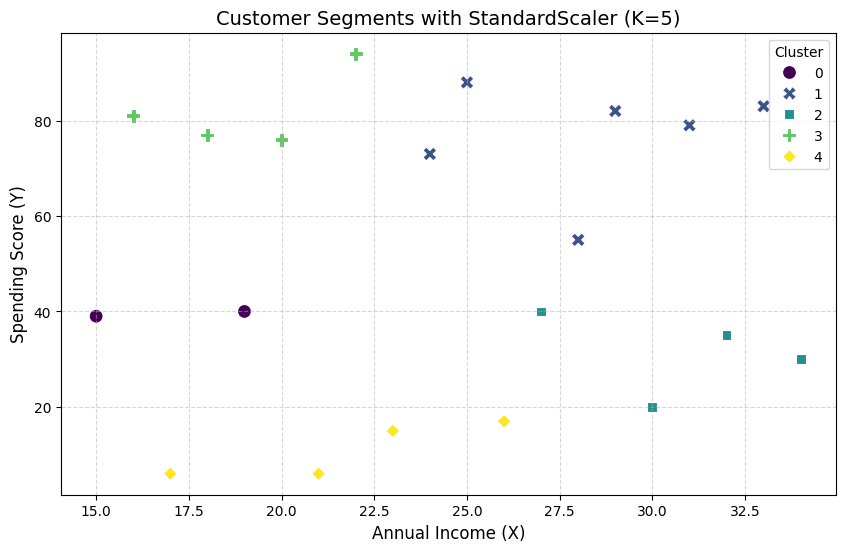

In [4]:
# Generate 2D Scatter plot (k=5)
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x="Annual Income (X)",
    y="Spending Score (Y)",
    hue="Cluster",
    palette="viridis",
    data=df_k5,
    s=100,
    style="Cluster"
)
plt.title("Customer Segments with StandardScaler (K=5)", fontsize=14)
plt.xlabel("Annual Income (X)", fontsize=12)
plt.ylabel("Spending Score (Y)", fontsize=12)
plt.legend(title="Cluster")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [5]:
# Step 5: Compute cluster centers (in original scale) (for k=3)
centers_scaled = kmeans_3.cluster_centers_
centers = scaler.inverse_transform(centers_scaled)

print('-- K-Means = 3 (Scaled) --  ')
print("Cluster assignments:")
print(df_k3[["Customer", "Cluster"]])

print("\nCluster centers (original scale):")
print(pd.DataFrame(centers, columns=X.columns))

print("\nWCSS:", kmeans_3.inertia_)

#for k=5
centers_scaled = kmeans_5.cluster_centers_
centers = scaler.inverse_transform(centers_scaled)

print('-- K-Means = 5 (Scaled) --  ')
print("Cluster assignments:")
print(df_k5[["Customer", "Cluster"]])

print("\nCluster centers (original scale):")
print(pd.DataFrame(centers, columns=X.columns))

print("\nWCSS:", kmeans_5.inertia_)

-- K-Means = 3 (Scaled) --  
Cluster assignments:
   Customer  Cluster
0        C1        2
1        C2        1
2        C3        2
3        C4        1
4        C5        2
5        C6        1
6        C7        2
7        C8        1
8        C9        2
9       C10        1
10      C11        1
11      C12        0
12      C13        0
13      C14        0
14      C15        1
15      C16        0
16      C17        0
17      C18        0
18      C19        0
19      C20        0

Cluster centers (original scale):
   Annual Income (X)  Spending Score (Y)
0             30.125           44.875000
1             22.000           81.571429
2             19.000           21.200000

WCSS: 13.434257417287204
-- K-Means = 5 (Scaled) --  
Cluster assignments:
   Customer  Cluster
0        C1        0
1        C2        3
2        C3        4
3        C4        3
4        C5        0
5        C6        3
6        C7        4
7        C8        3
8        C9        4
9       C10        1
10 

##Compare results between k=3 and k=5

The WCSS when k=3 is approximately 13.43 whereas the WCSS when k=5 is 6.13.
$$\frac{13.43 - 6.13}{13.43} \times 100 = 54.36\%$$

As such, when k=5, the model produces more compact clusters, with data points closer to their respective centroids. However, this does not necessarily establish K = 5 as the optimal number of clusters."

## Use the Elbow Method

k=1: WCSS = 40.00
k=2: WCSS = 23.06
k=3: WCSS = 13.43
k=4: WCSS = 7.57
k=5: WCSS = 6.13
k=6: WCSS = 4.43


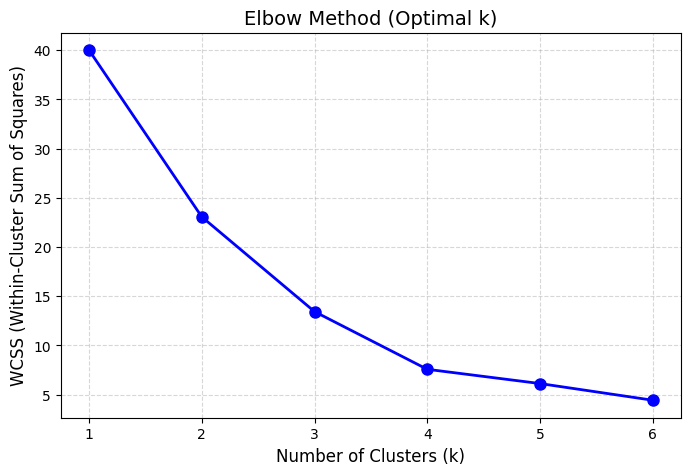

In [6]:
# Compute WCSS for k = 1 to 6
wcss = []
k_values = range(1, 7)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Print WCSS values for your report/table
for k, val in zip(k_values, wcss):
    print(f"k={k}: WCSS = {val:.2f}")

# Plotting the Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(k_values, wcss, marker='o', linestyle='-', color='b', linewidth=2, markersize=8)
plt.title('Elbow Method (Optimal k)', fontsize=14)
plt.xlabel('Number of Clusters (k)', fontsize=12)
plt.ylabel('WCSS (Within-Cluster Sum of Squares)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

From the plot, the most optimal number of cluster(k) is 4.
From the values, the optimal number of clusters is approximately k = 4. The WCSS decreases substantially as k increases from 1 to 4, indicating improved clustering compactness. However, beyond k = 4, the reduction in WCSS becomes considerably smaller. This suggests diminishing improvements from adding more clusters. Therefore, k = 4 is selected as a reasonable balance between cluster compactness and model simplicity

# Analyze Sensitivity to Initialization

In [7]:
# Sensitivity to Initialization
seeds = [0, 10, 42, 100, 123]

results_k3 = []
results_k5 = []

#Kmeans with k=3

for seed in seeds:
    kmeans = KMeans(n_clusters=3,random_state=seed,n_init=1)
    labels = kmeans.fit_predict(X_scaled)
    results_k3.append({"Random Seed": seed,"WCSS": kmeans.inertia_,"Cluster Assignments": labels})

# Display WCSS comparison
comparison_k3 = pd.DataFrame([
    {"Random Seed": result["Random Seed"],"WCSS": result["WCSS"]}
    for result in results_k3
])

display(comparison_k3)

#K-means with k=5

for seed in seeds:
    kmeans = KMeans(n_clusters=5,random_state=seed,n_init=1)
    labels = kmeans.fit_predict(X_scaled)
    results_k5.append({"Random Seed": seed,"WCSS": kmeans.inertia_,"Cluster Assignments": labels})

# Display WCSS comparison
comparison_k5 = pd.DataFrame([
    {"Random Seed": result["Random Seed"],"WCSS": result["WCSS"]}
    for result in results_k5
])

display(comparison_k5)

,Random Seed,WCSS
0,0,14.800685
1,10,13.789676
2,42,13.789676
3,100,13.789676
4,123,14.110608


,Random Seed,WCSS
0,0,6.532361
1,10,6.079453
2,42,6.265844
3,100,6.172813
4,123,5.964542


In [8]:
# Compare cluster assignments for K=3
assignments_k3 = pd.DataFrame({
    f"Seed {result['Random Seed']}":
    result["Cluster Assignments"]
    for result in results_k3
})

print("Cluster Assignment Comparison (K=3)")
display(assignments_k3)


# Compare cluster assignments for K=5
assignments_k5 = pd.DataFrame({
    f"Seed {result['Random Seed']}":
    result["Cluster Assignments"]
    for result in results_k5
})

print("Cluster Assignment Comparison (K=5)")
display(assignments_k5)

Cluster Assignment Comparison (K=3)


,Seed 0,Seed 10,Seed 42,Seed 100,Seed 123
0,2,2,2,1,2
1,2,1,0,0,2
2,1,2,2,1,1
3,2,1,0,0,2
4,2,2,2,1,2
5,2,1,0,0,2
6,1,2,2,1,1
7,0,1,0,0,2
8,1,2,2,1,1
9,0,1,0,0,2


Cluster Assignment Comparison (K=5)


,Seed 0,Seed 10,Seed 42,Seed 100,Seed 123
0,2,2,2,3,2
1,2,3,4,4,3
2,1,2,2,1,1
3,2,3,4,4,3
4,2,2,2,3,2
5,2,3,0,4,3
6,1,2,2,1,1
7,0,1,0,4,3
8,1,2,2,1,1
9,0,1,0,0,3


--kmeans when k=3--
Seed 42 vs Seed 0: ARI = 0.3180
Seed 42 vs Seed 10: ARI = 1.0000
Seed 42 vs Seed 100: ARI = 1.0000
Seed 42 vs Seed 123: ARI = 0.2908


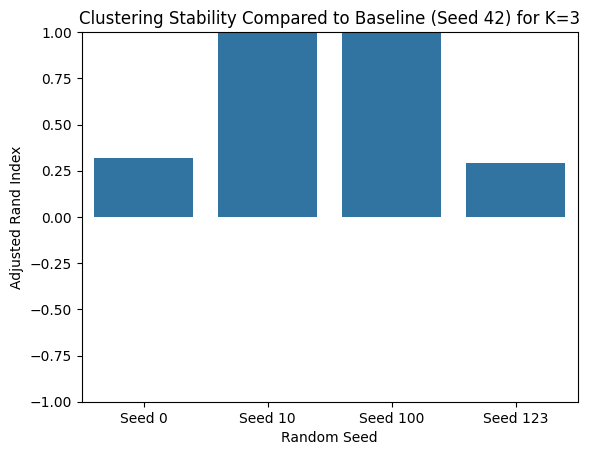

--kmeans when k=5--
Seed 42 vs Seed 0: ARI = 0.5491
Seed 42 vs Seed 10: ARI = 0.9072
Seed 42 vs Seed 100: ARI = 0.3766
Seed 42 vs Seed 123: ARI = 0.6195


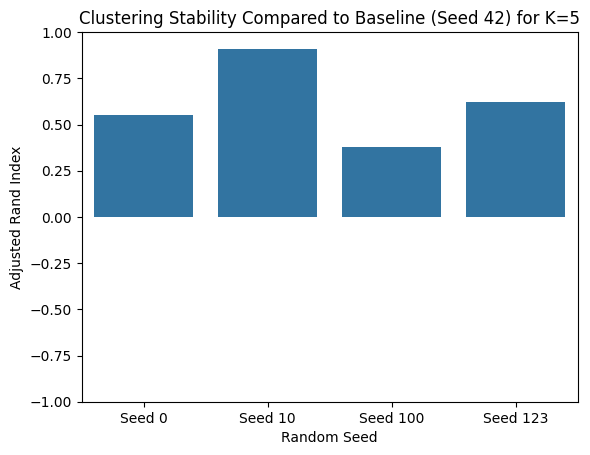

In [9]:
#comparison
# Use assignments_k3 (or assignments_k5 depending on which K you want to compare)
baseline = assignments_k3["Seed 42"]

print('--kmeans when k=3--')
for seed in ["Seed 0", "Seed 10", "Seed 100", "Seed 123"]:
    ari = adjusted_rand_score(baseline, assignments_k3[seed])
    print(f"Seed 42 vs {seed}: ARI = {ari:.4f}")

#correlation heatmap
comparison = pd.DataFrame({
    "Seed": ["Seed 0", "Seed 10", "Seed 100", "Seed 123"],
    "ARI": [
        adjusted_rand_score(assignments_k3["Seed 42"], assignments_k3[s])
        for s in ["Seed 0", "Seed 10", "Seed 100", "Seed 123"]
    ]
})

sns.barplot(data=comparison, x="Seed", y="ARI")

plt.title("Clustering Stability Compared to Baseline (Seed 42) for K=3")
plt.ylabel("Adjusted Rand Index")
plt.xlabel("Random Seed")
plt.ylim(-1, 1)
plt.show()

#for k=5
baseline = assignments_k5["Seed 42"]

print('--kmeans when k=5--')
for seed in ["Seed 0", "Seed 10", "Seed 100", "Seed 123"]:
    ari = adjusted_rand_score(baseline, assignments_k5[seed])
    print(f"Seed 42 vs {seed}: ARI = {ari:.4f}")

#correlation heatmap
comparison = pd.DataFrame({
    "Seed": ["Seed 0", "Seed 10", "Seed 100", "Seed 123"],
    "ARI": [
        adjusted_rand_score(assignments_k5["Seed 42"], assignments_k5[s])
        for s in ["Seed 0", "Seed 10", "Seed 100", "Seed 123"]
    ]
})

sns.barplot(data=comparison, x="Seed", y="ARI")


plt.title("Clustering Stability Compared to Baseline (Seed 42) for K=5")
plt.ylabel("Adjusted Rand Index")
plt.xlabel("Random Seed")
plt.ylim(-1, 1)
plt.show()

Compare cluster assignments and WSCC:

When k = 3, comparing Seed 42 against the other initialisations, Seeds 10 and 100 achieved an ARI of 1.000, indicating identical clustering structures to the baseline. In contrast, Seeds 0 and 123 achieved ARI values of 0.3180 and 0.2908, respectively, indicating lower agreement.

The WCSS values also varied across initialisations, ranging from 13.7897 to 14.8007. Seeds 10, 42 and 100 achieved the same WCSS of 13.7897.

When k = 5, Seed 10 achieved the highest ARI of 0.9072, indicating strong agreement with the baseline. Seed 100 showed the lowest agreement, with an ARI of 0.3766. The WCSS ranged from 5.9645 to 6.5324, with Seed 123 achieving the lowest value.

These variations occur because K-Means initially selects random cluster centroids. Different initial positions can lead to different assignments and convergence to different local minima. Consequently, both cluster assignments and WCSS may vary depending on the random initialisation.


#Exercise 2

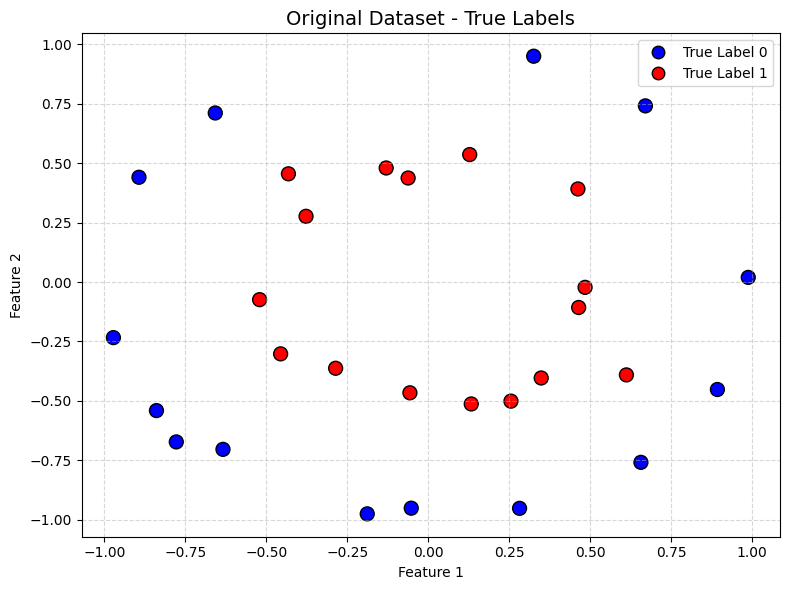

In [13]:

#dataset + plot
data = {
    "Point": list(range(1, 31)),
    "Feature1": [
        0.1331, 0.4648, -0.5205, 0.4625, -0.9720,
        -0.8390, 0.3491, -0.4556, 0.2823, 0.9885,
        -0.0522, -0.4315, 0.1283, -0.0563, 0.4846,
        -0.1881, 0.3259, -0.8930, -0.7778, 0.6570,
        -0.0618, 0.6709, -0.6336, -0.2857, -0.1296,
        0.2557, -0.6574, 0.8932, -0.3771, 0.6122
    ],
    "Feature2": [
        -0.5126, -0.1070, -0.0741, 0.3913, -0.2337,
        -0.5404, -0.4034, -0.3020, -0.9513, 0.0195,
        -0.9507, 0.4549, 0.5358, -0.4657, -0.0224,
        -0.9745, 0.9493, 0.4404, -0.6721, -0.7580,
        0.4373, 0.7405, -0.7034, -0.3625, 0.4794,
        -0.5007, 0.7107, -0.4518, 0.2763, -0.3904
    ],
    "True Label": [
        1, 1, 1, 1, 0, 0, 1, 1, 0, 0,
        0, 1, 1, 1, 1, 0, 0, 0, 0, 0,
        1, 0, 0, 1, 1, 1, 0, 0, 1, 1
    ]
}

df_circles = pd.DataFrame(data)

# Plot original dataset with true labels
plt.figure(figsize=(8, 6))

colors = df_circles["True Label"].map({
    0: "blue",
    1: "red"
})

plt.scatter(
    df_circles["Feature1"],
    df_circles["Feature2"],
    c=colors,
    s=100,
    edgecolors="black"
)

plt.title("Original Dataset - True Labels", fontsize=14)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.legend(handles=[
    Line2D(
        [0], [0],
        marker='o',
        color='w',
        markerfacecolor='blue',
        markeredgecolor='black',
        markersize=9,
        label='True Label 0'
    ),
    Line2D(
        [0], [0],
        marker='o',
        color='w',
        markerfacecolor='red',
        markeredgecolor='black',
        markersize=9,
        label='True Label 1'
    )
])

plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [14]:
#apply kmeans, k = 2
# Select features
# Select only the two features
X = df_circles[["Feature1", "Feature2"]]

# Apply K-Means
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Predict cluster assignments
df_circles["KMeans Cluster"] = kmeans.fit_predict(X)

# Store cluster centers
centers = kmeans.cluster_centers_

# Display results
print("\nK-MEANS CLUSTERING RESULTS")
print(df_circles)

print("\nCluster Centers:")
print(centers)

print("\nWCSS (Inertia):")
print(kmeans.inertia_)

print("\nCluster Sizes:")
print(df_circles["KMeans Cluster"].value_counts())


K-MEANS CLUSTERING RESULTS
    Point  Feature1  Feature2  True Label  KMeans Cluster
0       1    0.1331   -0.5126           1               1
1       2    0.4648   -0.1070           1               0
2       3   -0.5205   -0.0741           1               1
3       4    0.4625    0.3913           1               0
4       5   -0.9720   -0.2337           0               1
5       6   -0.8390   -0.5404           0               1
6       7    0.3491   -0.4034           1               1
7       8   -0.4556   -0.3020           1               1
8       9    0.2823   -0.9513           0               1
9      10    0.9885    0.0195           0               0
10     11   -0.0522   -0.9507           0               1
11     12   -0.4315    0.4549           1               0
12     13    0.1283    0.5358           1               0
13     14   -0.0563   -0.4657           1               1
14     15    0.4846   -0.0224           1               0
15     16   -0.1881   -0.9745           0   

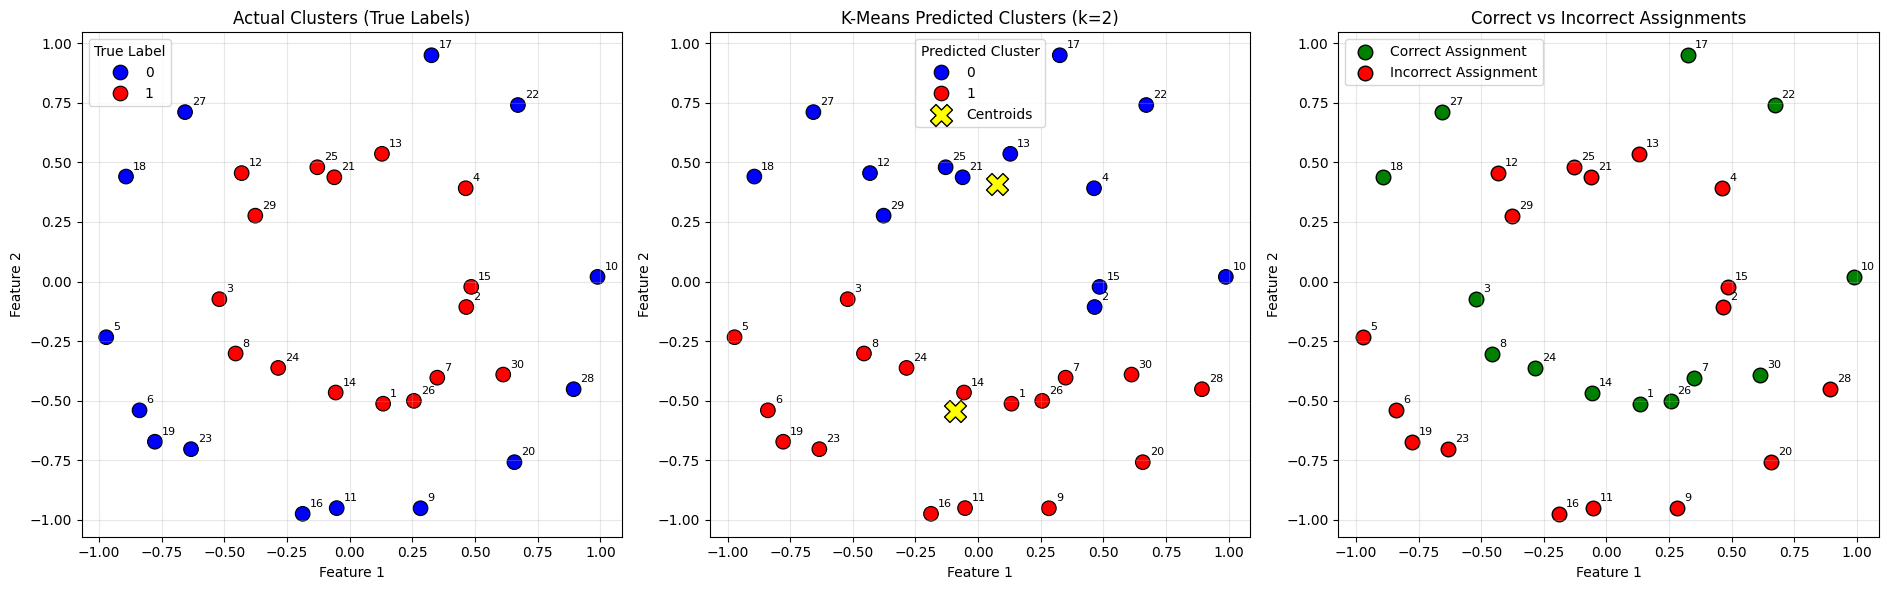

In [15]:
#evaluate kmeans clustering + visualisation

# Find optimal mapping between K-Means clusters and true labels
cm = contingency_matrix(
    df_circles["True Label"],
    df_circles["KMeans Cluster"]
)

row_ind, col_ind = linear_sum_assignment(-cm)

mapping = dict(zip(col_ind, row_ind))

# Compare True Label directly with KMeans Cluster
df_circles["Correct"] = (
    df_circles["True Label"] ==
    df_circles["KMeans Cluster"]
)

# Calculate ARI
ari = adjusted_rand_score(
    df_circles["True Label"],
    df_circles["KMeans Cluster"]
)

fig, axes = plt.subplots(1, 3, figsize=(19, 6))

#visualisation
# PLOT 1: ACTUAL GROUND TRUTH

sns.scatterplot(
    data=df_circles,
    x="Feature1",
    y="Feature2",
    hue="True Label",
    palette={0: "blue", 1: "red"},
    s=110,
    edgecolor="black",
    ax=axes[0]
)
for _, row in df_circles.iterrows():
    axes[0].annotate(
        str(row["Point"]),
        (row["Feature1"], row["Feature2"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

axes[0].set_title("Actual Clusters (True Labels)")
axes[0].set_xlabel("Feature 1")
axes[0].set_ylabel("Feature 2")
axes[0].legend(title="True Label")
axes[0].grid(alpha=0.3)


# PLOT 2: K-MEANS PREDICTED CLUSTERS

sns.scatterplot(
    data=df_circles,
    x="Feature1",
    y="Feature2",
    hue="KMeans Cluster",
    palette={0: "blue", 1: "red"},
    s=110,
    edgecolor="black",
    ax=axes[1]
)
# Add point numbers
for _, row in df_circles.iterrows():
    axes[1].annotate(
        str(row["Point"]),
        (row["Feature1"], row["Feature2"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

# Plot cluster centroids
axes[1].scatter(
    centers[:, 0],
    centers[:, 1],
    marker="X",
    s=250,
    color="yellow",
    edgecolor="black",
    label="Centroids"
)


axes[1].set_title("K-Means Predicted Clusters (k=2)")
axes[1].set_xlabel("Feature 1")
axes[1].set_ylabel("Feature 2")
axes[1].legend(title="Predicted Cluster")
axes[1].grid(alpha=0.3)

# PLOT 3: CORRECT VS INCORRECT ASSIGNMENTS

# Separate correct and incorrect points
correct_points = df_circles[df_circles["Correct"] == True]
incorrect_points = df_circles[df_circles["Correct"] == False]

# Plot
axes[2].scatter(
    correct_points["Feature1"],
    correct_points["Feature2"],
    color="green",
    s=110,
    edgecolor="black",
    label="Correct Assignment"
)

axes[2].scatter(
    incorrect_points["Feature1"],
    incorrect_points["Feature2"],
    color="red",
    s=110,
    edgecolor="black",
    label="Incorrect Assignment"
)

# Add point numbers
for _, row in df_circles.iterrows():
    axes[2].annotate(
        str(row["Point"]),
        (row["Feature1"], row["Feature2"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

axes[2].set_title("Correct vs Incorrect Assignments")
axes[2].set_xlabel("Feature 1")
axes[2].set_ylabel("Feature 2")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [16]:
# Display comparison
print(
    df_circles[
        ["Point", "True Label", "KMeans Cluster", "Correct"]
    ].to_string(index=False)
)

 Point  True Label  KMeans Cluster  Correct
     1           1               1     True
     2           1               0    False
     3           1               1     True
     4           1               0    False
     5           0               1    False
     6           0               1    False
     7           1               1     True
     8           1               1     True
     9           0               1    False
    10           0               0     True
    11           0               1    False
    12           1               0    False
    13           1               0    False
    14           1               1     True
    15           1               0    False
    16           0               1    False
    17           0               0     True
    18           0               0     True
    19           0               1    False
    20           0               1    False
    21           1               0    False
    22           0              

Question: Discuss why spherical assumption makes K-Means unsuitable for complex-shaped
clusters.

K-Means assumes that clusters are roughly spherical and groups data points based on their distance from the cluster centres. For complex-shaped clusters, such as two interlocking circles, K-Means cannot correctly separate the groups because points from different clusters may be closer to the same centre. As a result, it may assign points to the wrong clusters and produce inaccurate results.